# AP 155 Lab Exercise
---
## Exercise 8: Minimization

_Instructions_: 
- **Report figure:** A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm.  
- **Report discussion:** What happens if a number other than the golden ratio is used to perform the *golden* section search algorithm?
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Iniego, Angel Nicole V.
- _Student No._: 2024-09622
- _Section_: THR-TX-X

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view?usp=sharing) (Note: percentages may still be tweaked)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_:_

---
## Section 1: Report

### Report figure

<img src="../Figures/08_Comparison.png" alt="Combined Plots for phi(x) and f(x)." width=100% caption="Combined Plots">
Figure 1. Combined Plots for phi(x) and f(x).


EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.


### Report discussion

What happends if a number other than the golden ratio is used is that the spacing would be uneven, and so we cannot reuse the function in the next step. The reason why tthe golden ratio method is efficient is because we can reuse it for until the terminating conditions are met, which are when the min/max is found within the tolerance or if the max iterations have been reached. The workaround for not using the golden ratio could be to predetermine the number of steps the iteration would go. 

### Other comments
- This is a chill activity. I like.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Minimization

Consider the following equations:

Eq. 5.91
$$
\phi(x) = x^4 - 9x^3 + 25x^2 - 24x + 4
$$

Eq. 5.145
$$
f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 - 4xe^x + 8x + 4e^x - 8
$$


1. Plot each of the functions. Get a rough estimate of the local minima and maxima
2. Implement 5.5.2.2 (golden section search), then determine the local minima and maxima of Eq. 5.91 and Eq. 5.145.
3. Report figure: A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm. 

In [2]:
# Implementing the Golden Ratio minima-finding mechanism.
import matplotlib.pyplot as plt
import numpy as np

In [3]:
def phi(x):
    """ This is Equatiion 5.91 """
    return x**4 -9*x**3 + 25*x**2 - 24*x + 4

def phi_prime(x):
    """ This is the derivative of Equation 5.91 """
    return 4*x**3 - 27*x**2 + 50*x - 24

def f(x):
    """ This is Equation 5.145  """
    return - x**5 + 4*x**4 - 4*x**3 + x**2*np.exp(x) - 2*x**2 - 4*x*np.exp(x) + 8*x + 4*np.exp(x) - 8

def f_prime(x):
    """ This is the derivative of Equation 5.145 """
    return -5*x**4 + 16*x**3 - 12*x**2 - 4*x + 2*x*np.exp(x) + x**2*np.exp(x) + 8

In [4]:
def golden(phi, x0, x1, kmax=200, tol=1.e-8):
    """ This is the Gezerlis implementation of the program. """
    varphi = 0.5*(1 + np.sqrt(5))
    for k in range(1,kmax):
        x2 = x0 + (x1-x0)/(varphi+1)
        x3 = x0 + (x1-x0)*varphi/(varphi+1)
        
        if phi(x3) < phi(x2):
            x0 = x2
        else:
            x1 = x3
            
        xnew = (x0+x1)/2
        xdiff = abs(x1-x0)
        rowf = "{0:2d} {1:1.16f} {2:1.16f} {3:1.16f}"
        # print(rowf.format(k, xnew, xdiff, phi(xnew)))

        if abs(xdiff) < tol:
            break
    else:
        xnew = None
    return xnew

def golden_max(phi, x0, x1, kmax=200, tol=1.e-8):
    """ For this function, we instead put > so the maximum is targetted. """
    varphi = 0.5*(1 + np.sqrt(5))
    for k in range(1,kmax):
        x2 = x0 + (x1-x0)/(varphi+1)
        x3 = x0 + (x1-x0)*varphi/(varphi+1)
        
        if phi(x3) > phi(x2):
            x0 = x2
        else:
            x1 = x3
            
        xnew = (x0+x1)/2
        xdiff = abs(x1-x0)
        rowf = "{0:2d} {1:1.16f} {2:1.16f} {3:1.16f}"
        # print(rowf.format(k, xnew, xdiff, phi(xnew)))

        if abs(xdiff) < tol:
            break
    else:
        xnew = None
    return xnew

In [5]:
# For the function phi(X), at this point, I chose the bound to be += 0.1
# The minima for phi(x) occur at: (0.75,-3.41797) and (4,-12)
a = golden(phi, 0.65,0.85)
b = golden(phi, 3.9, 4.1)

In [6]:
# For the function f(X)
# I put separate functions to set the values for plotting.
# These can be checked using print(c) etc. 
c = golden(f, -0.7, -0.65)
d = golden(f, 4.1,4.2)

In [7]:
phi_max = golden_max(phi, 1.5,2.5)

In [8]:
f_max = golden_max(f, 1.5,2.5)

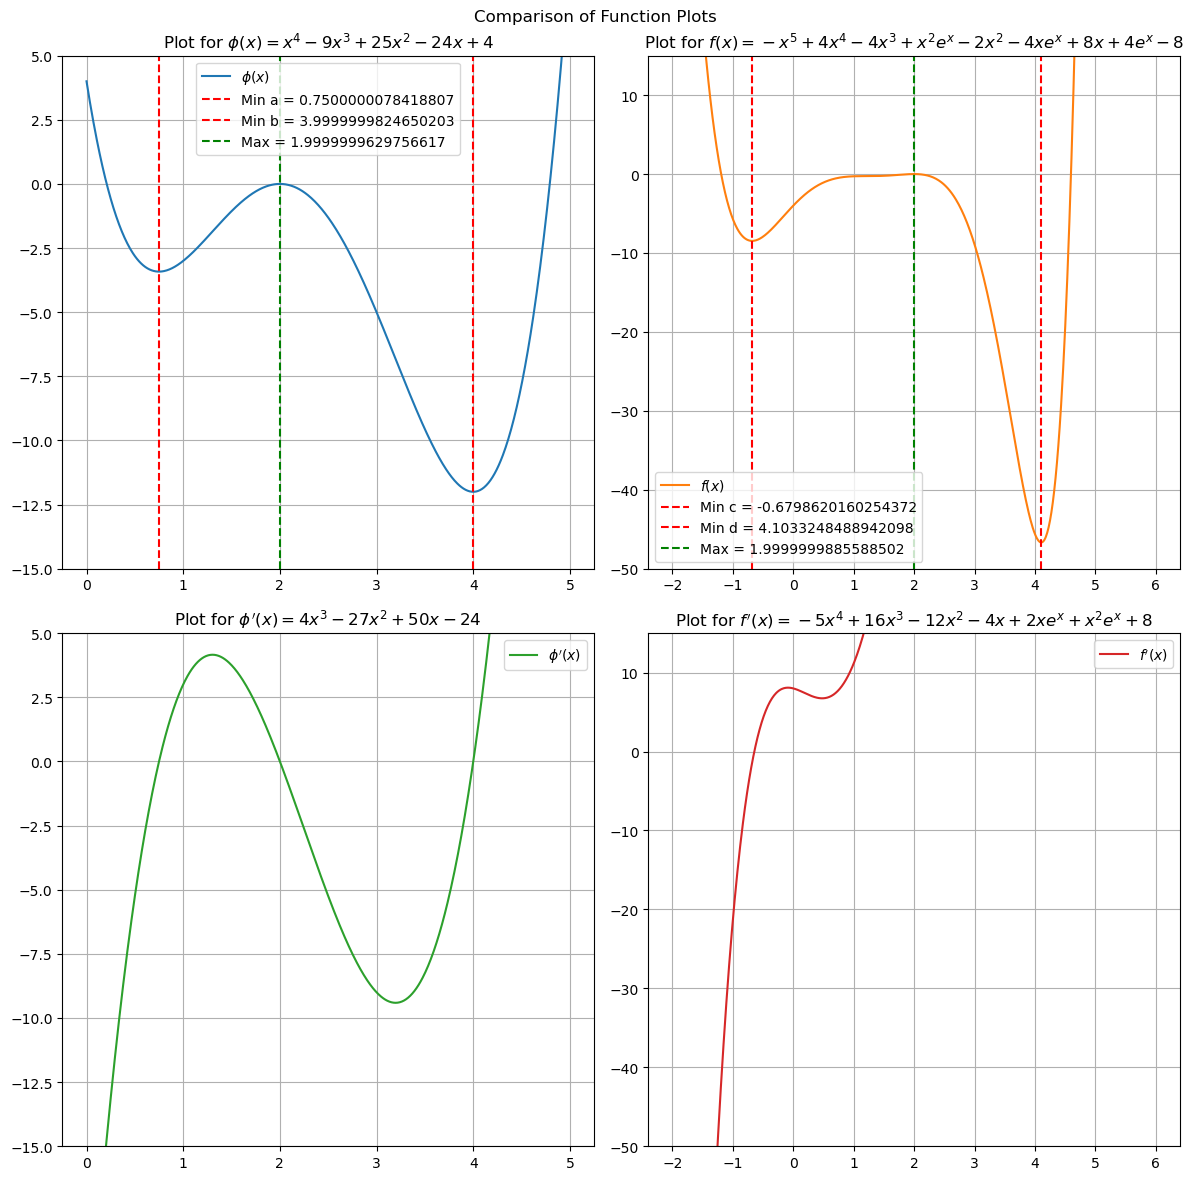

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# sample incomplete 2 by 2 plot 

x1 = np.linspace(0, 5, 700)
x2 = np.linspace(-2, 6, 700)

fig, axs = plt.subplots(2, 2, figsize=(12, 12))
fig.suptitle("Comparison of Function Plots")

axs[0, 0].plot(x1, phi(x1), label=r'$\phi(x)$')
axs[0, 0].axvline(x=a, color='red', linestyle='--', label=f'Min a = {a:.16f}') 
axs[0, 0].axvline(x=b, color='red', linestyle='--', label=f'Min b = {b:.16f}')
axs[0, 0].axvline(x=phi_max, color='green', linestyle='--', label=f'Max = {phi_max:.16f}')
axs[0, 0].set_title(r"Plot for $\phi(x) = x^4 - 9x^3 + 25x^2 - 24x + 4$")
axs[0, 0].set_ylim(-15, 5)
axs[0, 0].grid()
axs[0, 0].legend(loc='best')   


axs[0, 1].plot(x2, f(x2), 'tab:orange', label=r'$f(x)$')
axs[0, 1].axvline(x=c, color='red', linestyle='--', label=f'Min c = {c:.16f}')
axs[0, 1].axvline(x=d, color='red', linestyle='--', label=f'Min d = {d:.16f}')
axs[0, 1].axvline(x=f_max, color='green', linestyle='--', label=f'Max = {f_max:.16f}')
axs[0, 1].set_title(r"Plot for $f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 - 4xe^x + 8x + 4e^x - 8$")
axs[0, 1].set_ylim(-50, 15)
axs[0, 1].grid()
axs[0, 1].legend(loc='best')   


axs[1, 0].plot(x1, phi_prime(x1), 'tab:green', label=r"$\phi'(x)$")
axs[1, 0].set_title(r"Plot for $\phi'(x) = 4x^3-27x^2+50x-24 $")
axs[1, 0].set_ylim(-15, 5)
axs[1, 0].grid()
axs[1, 0].legend(loc='best')


axs[1, 1].plot(x2, f_prime(x2), 'tab:red', label=r"$f'(x)$")
axs[1, 1].set_title(r"Plot for $f'(x) = -5x^4 + 16x^3 - 12x^2 - 4x + 2xe^x + x^2e^x + 8 $")
axs[1, 1].set_ylim(-50, 15)
axs[1, 1].grid()
axs[1, 1].legend(loc='best')

plt.tight_layout()
plt.savefig("08_Comparison.png", dpi=300, bbox_inches="tight")
plt.show()

#### Problem 1 code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---